# Eigenvalues and Eigenvectors

A computational companion to [Eigenvalues and Eigenvectors](https://fjhickernell.github.io/MATH332Fall2026/slides/09-eigenvalues-and-eigenvectors.html). Find directions preserved by a matrix, compare eigenspaces, and use eigenbasis coordinates to predict repeated actions.

The deck supplies the mathematical exposition. Predict each result before running its cell. Exact SymPy identities check the worked examples; numerical plots illustrate their geometry rather than prove a general theorem.

## Running this notebook

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fjhickernell/MATH332Fall2026/blob/main/notebooks/demonstrations/09-eigenvalues-and-eigenvectors.ipynb)

Run all cells in order with the **qmcpy** kernel. The setup cell changes the environment only in Colab, where it installs the course's recorded `classlib` checkout. It leaves the working directory unchanged. Colab does not save edits to the course repository; save a copy in Drive to retain your experiments.

In [1]:
from pathlib import Path
import subprocess
import sys
import time

NOTEBOOK_START_TIME = time.perf_counter()

colab = "google.colab" in sys.modules
if colab:
    print("Setting up this course's recorded classlib; this may take a minute …")
    course_checkout = Path("/content/MATH332Fall2026")
    if not course_checkout.exists():
        subprocess.run(
            [
                "git", "clone", "--quiet", "--depth", "1",
                "https://github.com/fjhickernell/MATH332Fall2026.git",
                str(course_checkout),
            ],
            check=True,
        )
    subprocess.run(
        [
            "git", "-C", str(course_checkout),
            "-c", "submodule.classlib.url=https://github.com/fjhickernell/HickernellAcademicLib.git",
            "submodule", "update", "--init", "--recursive", "classlib",
        ],
        check=True,
    )
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", str(course_checkout / "classlib")],
        check=True,
    )
    print("Colab setup complete.")

In [2]:
import numpy as np
import sympy as sp
from sympy import Matrix
import matplotlib.pyplot as plt
import classlib as cl
from IPython.display import display, Markdown

%matplotlib inline
cl.nbviz.init(use_tex=False)
sp.init_printing()
np.set_printoptions(precision=6, suppress=True)
blue = cl.nbviz.TOL_BRIGHT["blue"]
red = cl.nbviz.TOL_BRIGHT["red"]
green = cl.nbviz.TOL_BRIGHT["green"]
lam = sp.symbols("lambda")

def show(label, value):
    display(Markdown(label))
    display(value)

## 1. Which directions stay on their lines?

Use the deck's $\mathsf A=\begin{bmatrix}2&1\\1&2\end{bmatrix}$. Predict the images of $v_1=(1,1)^\top$, $v_2=(1,-1)^\top$, and $e_1=(1,0)^\top$ before running the cell. The two panels use the same scale.

Images of v1, v2, e1 (columns)

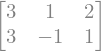

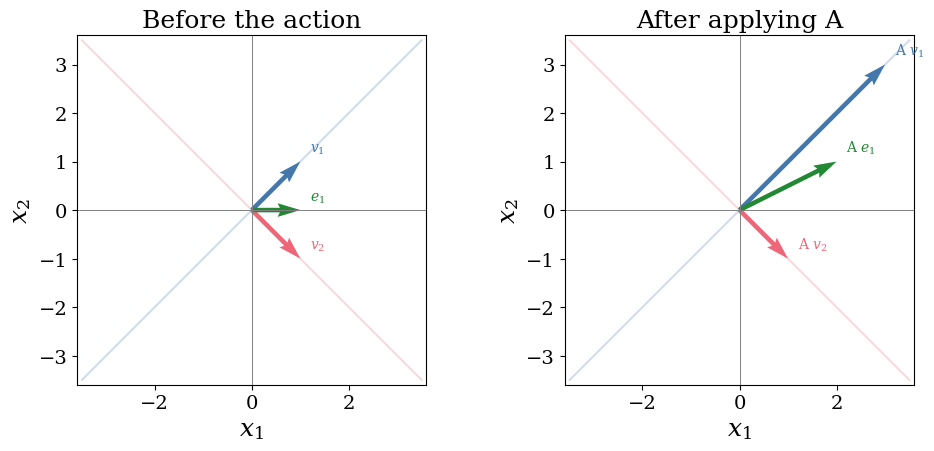

In [3]:
A = Matrix([[2, 1], [1, 2]])
v1, v2, e1 = Matrix([1, 1]), Matrix([1, -1]), Matrix([1, 0])
assert A*v1 == 3*v1 and A*v2 == v2
assert Matrix.hstack(e1, A*e1).det() != 0
show("Images of v1, v2, e1 (columns)", A*Matrix.hstack(v1, v2, e1))

fig, axes = plt.subplots(1, 2, figsize=(10, 4.6))
for ax, action, title in zip(axes, (sp.eye(2), A), ("Before the action", "After applying A")):
    line = np.array([-3.5, 3.5])
    ax.plot(line, line, color=blue, alpha=0.25)
    ax.plot(line, -line, color=red, alpha=0.25)
    for vector, label, color in ((v1, r"$v_1$", blue), (v2, r"$v_2$", red), (e1, r"$e_1$", green)):
        endpoint = np.array(action*vector, dtype=float).ravel()
        ax.quiver(0, 0, *endpoint, angles="xy", scale_units="xy", scale=1,
                  color=color, width=0.013)
        prefix = "" if action == sp.eye(2) else "A "
        ax.annotate(prefix+label, endpoint, xytext=(7, 7), textcoords="offset points", color=color)
    ax.axhline(0, color="gray", linewidth=0.7)
    ax.axvline(0, color="gray", linewidth=0.7)
    ax.set(xlim=(-3.6, 3.6), ylim=(-3.6, 3.6), xlabel=r"$x_1$", ylabel=r"$x_2$", title=title)
    ax.set_aspect("equal")
fig.tight_layout()
plt.show()

## 2. Roots give scale factors; null spaces give directions

Compute the monic characteristic polynomial $p_{\mathsf A}(\lambda)=\det(\lambda\mathsf I-\mathsf A)$. For each root, solve a different homogeneous system. The basis vectors below are nonzero; the eigenspace $\operatorname{null}(\mathsf A-\lambda\mathsf I)$ also includes zero.

Characteristic polynomial

A - (1) I

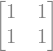

Eigenspace basis for lambda = 1 (columns)

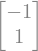

A - (3) I

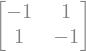

Eigenspace basis for lambda = 3 (columns)

Trace and determinant checks pass, with algebraic multiplicities counted.


In [4]:
characteristic = sp.factor(A.charpoly(lam).as_expr())
show("Characteristic polynomial", characteristic)
eigenvalues = sp.roots(characteristic, lam)
assert eigenvalues == {sp.Integer(1): 1, sp.Integer(3): 1}
for eigenvalue, multiplicity in sorted(eigenvalues.items()):
    shifted = A-eigenvalue*sp.eye(A.rows)
    basis = shifted.nullspace()
    show(f"A - ({eigenvalue}) I", shifted)
    show(f"Eigenspace basis for lambda = {eigenvalue} (columns)", Matrix.hstack(*basis))
    assert len(basis) == A.rows-shifted.rank()
    assert all(v != sp.zeros(A.rows, 1) and A*v == eigenvalue*v for v in basis)
assert sum(value*count for value, count in eigenvalues.items()) == sp.trace(A)
assert sp.prod(value**count for value, count in eigenvalues.items()) == A.det()
print("Trace and determinant checks pass, with algebraic multiplicities counted.")

### The same repeated root can give different eigenspace dimensions

Compare $\mathsf S=2\mathsf I_2$ and $\mathsf J=\begin{bmatrix}2&1\\0&2\end{bmatrix}$. Both have characteristic polynomial $(\lambda-2)^2$. Predict how many independent eigenvectors each supplies. Counting repeated roots and counting independent eigenvectors answer different questions.

S: characteristic polynomial

S: basis of E_2 (columns)

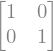

S: algebraic multiplicity 2; geometric multiplicity 2; diagonalizable: True


J: characteristic polynomial

J: basis of E_2 (columns)

J: algebraic multiplicity 2; geometric multiplicity 1; diagonalizable: False


In [5]:
S = 2*sp.eye(2)
J = Matrix([[2, 1], [0, 2]])
for label, matrix in (("S", S), ("J", J)):
    polynomial = sp.factor(matrix.charpoly(lam).as_expr())
    eigenspace = (matrix-2*sp.eye(2)).nullspace()
    show(f"{label}: characteristic polynomial", polynomial)
    show(f"{label}: basis of E_2 (columns)", Matrix.hstack(*eigenspace))
    print(f"{label}: algebraic multiplicity 2; geometric multiplicity {len(eigenspace)}; "
          f"diagonalizable: {len(eigenspace) == matrix.rows}")
    assert polynomial == (lam-2)**2
assert len((S-2*sp.eye(2)).nullspace()) == 2
assert len((J-2*sp.eye(2)).nullspace()) == 1

### Optional: a generalized eigenvector supplies a missing basis direction

This short extension may be omitted in class. A nonzero vector $w$ is a **generalized eigenvector** for $\lambda$ if $(\mathsf A-\lambda\mathsf I)^k w=0$ for some positive integer $k$. Ordinary eigenvectors have $k=1$; a rank-two generalized eigenvector satisfies $(\mathsf A-\lambda\mathsf I)^2w=0$ but $(\mathsf A-\lambda\mathsf I)w\ne0$.

For the preceding $\mathsf J$, take $v=(1,0)^\top$ and $w=(0,1)^\top$. Predict the chain
\begin{equation*}
(\mathsf J-2\mathsf I)w=v,\qquad (\mathsf J-2\mathsf I)v=0.
\end{equation*}
The vectors form a basis $\mathsf G=[v\ w]$, although $w$ is not an ordinary eigenvector. Its action is $\mathsf Jw=2w+v$: the extra term keeps the matrix upper triangular rather than diagonal. Generalized eigenvectors can extend the available eigendirections without making the matrix diagonalizable. We do not develop a general Jordan-form algorithm here.

Columns: (J-2I)v, (J-2I)w, (J-2I)^2w

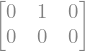

Generalized-eigenvector basis G = [v w]

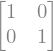

Matrix G^(-1) J G: upper triangular, not diagonal

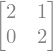

w is not an ordinary eigenvector: J w = 2 w + v.


In [6]:
shifted_J = J-2*sp.eye(2)
v = Matrix([1, 0])
w = Matrix([0, 1])
G = Matrix.hstack(v, w)
assert shifted_J*v == sp.zeros(2, 1)
assert shifted_J*w == v and shifted_J*w != sp.zeros(2, 1)
assert shifted_J**2*w == sp.zeros(2, 1)
assert G.det() != 0
assert J*w == 2*w+v
assert G.inv()*J*G == Matrix([[2, 1], [0, 2]])
show("Columns: (J-2I)v, (J-2I)w, (J-2I)^2w",
     Matrix.hstack(shifted_J*v, shifted_J*w, shifted_J**2*w))
show("Generalized-eigenvector basis G = [v w]", G)
show("Matrix G^(-1) J G: upper triangular, not diagonal", G.inv()*J*G)
print("w is not an ordinary eigenvector: J w = 2 w + v.")

## 3. Change coordinates, scale, reconstruct

Put the deck's two eigenvectors into $\mathsf V=[v_1\ v_2]$ and the matching eigenvalues into $\mathsf D=\operatorname{diag}(3,1)$. For $x=(4,2)^\top$, predict $\mathsf V^{-1}x$, then $\mathsf D\mathsf V^{-1}x$, and finally $\mathsf A x$.

Eigenbasis matrix V

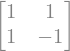

Input eigenbasis coordinates

Output eigenbasis coordinates

Output reconstructed in standard coordinates

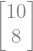

A^5 from independent scalar powers

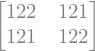

In [7]:
V = Matrix.hstack(v1, v2)
D = sp.diag(3, 1)
x = Matrix([4, 2])
coordinates = V.inv()*x
scaled_coordinates = D*coordinates
reconstructed = V*scaled_coordinates
show("Eigenbasis matrix V", V)
show("Input eigenbasis coordinates", coordinates)
show("Output eigenbasis coordinates", scaled_coordinates)
show("Output reconstructed in standard coordinates", reconstructed)
assert V.det() != 0 and A*V == V*D
assert coordinates == Matrix([3, 1])
assert reconstructed == A*x == Matrix([10, 8])
assert V.inv()*A*V == D

for k in (0, 1, 2, 5):
    assert A**k == V*(D**k)*V.inv()
show("A^5 from independent scalar powers", V*(D**5)*V.inv())

## 4. A fixed component plus a decaying component

In the deck's population model, 20% of group 1 moves to group 2 and 30% of group 2 moves to group 1 at each step:

\begin{equation*}
\mathsf T=\begin{bmatrix}4/5&3/10\\1/5&7/10\end{bmatrix},\qquad x_0=\begin{bmatrix}100\\0\end{bmatrix}.
\end{equation*}

Columns describe where each group's population goes. Predict the total population and long-run split. The model treats counts as continuous quantities or expected counts, so fractional values are allowed.

Initial eigenbasis coordinates

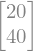

Population after k steps

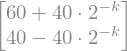

Rows: step, group 1, group 2

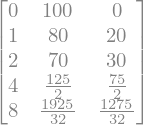

Limiting population

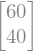

In [8]:
T = Matrix([[sp.Rational(4, 5), sp.Rational(3, 10)],
            [sp.Rational(1, 5), sp.Rational(7, 10)]])
V_population = Matrix([[3, 1], [2, -1]])
D_population = sp.diag(1, sp.Rational(1, 2))
x0 = Matrix([100, 0])
c0 = V_population.inv()*x0
show("Initial eigenbasis coordinates", c0)
assert c0 == Matrix([20, 40])
assert T*V_population == V_population*D_population
assert Matrix([[1, 1]])*T == Matrix([[1, 1]])

k = sp.symbols("k", integer=True, nonnegative=True)
xk = Matrix([60+40*sp.Rational(1, 2)**k, 40-40*sp.Rational(1, 2)**k])
show("Population after k steps", xk)
assert sp.simplify(T*xk-xk.subs(k, k+1)) == sp.zeros(2, 1)
assert xk.subs(k, 0) == x0
assert sp.simplify(sum(xk)) == 100
for step in (0, 1, 2, 4, 8):
    assert T**step*x0 == xk.subs(k, step)
show("Rows: step, group 1, group 2", Matrix([[step, *xk.subs(k, step)] for step in (0, 1, 2, 4, 8)]))
equilibrium = xk.applyfunc(lambda entry: sp.limit(entry, k, sp.oo))
show("Limiting population", equilibrium)
assert equilibrium == Matrix([60, 40]) and T*equilibrium == equilibrium

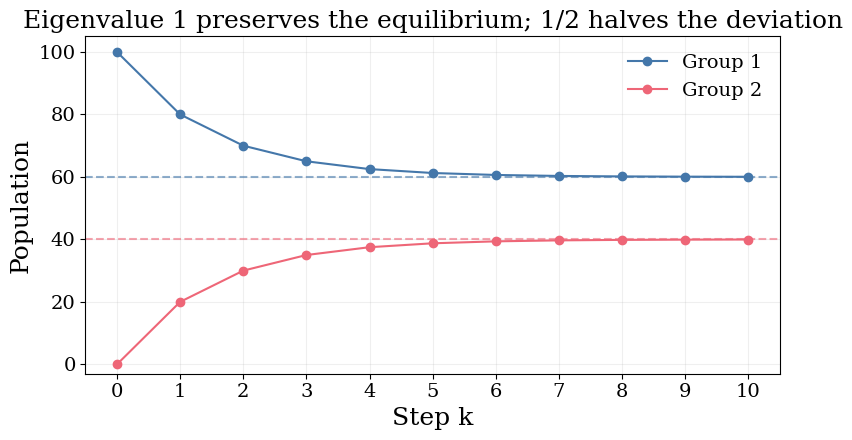

In [9]:
steps = np.arange(11)
populations = np.array([np.array(xk.subs(k, int(step)), dtype=float).ravel() for step in steps])
fig, ax = plt.subplots(figsize=(8, 4.5))
for j, color in enumerate((blue, red)):
    ax.plot(steps, populations[:, j], "o-", color=color, label=f"Group {j+1}")
    ax.axhline(float(equilibrium[j]), color=color, linestyle="--", alpha=0.6)
ax.set(xlabel="Step k", ylabel="Population", title="Eigenvalue 1 preserves the equilibrium; 1/2 halves the deviation",
       xticks=steps, ylim=(-3, 105))
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

## 5. A real rotation can need complex eigenvectors

The quarter turn $\mathsf R=\begin{bmatrix}0&-1\\1&0\end{bmatrix}$ has no real eigendirection. Over $\mathbb C$, check eigenvalues $i,-i$ and the deck's conjugate eigenvectors. Do not interpret these complex columns as arrows in the real plane.

Quarter-turn characteristic polynomial

Complex eigenvectors (columns)

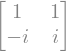

Complex coordinates of a real vector

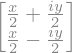

The conjugate pair reconstructs the real quarter-turn action.


In [10]:
R = Matrix([[0, -1], [1, 0]])
V_complex = Matrix([[1, 1], [-sp.I, sp.I]])
D_complex = sp.diag(sp.I, -sp.I)
show("Quarter-turn characteristic polynomial", sp.factor(R.charpoly(lam).as_expr()))
show("Complex eigenvectors (columns)", V_complex)
assert R.charpoly(lam).as_expr() == lam**2+1
assert R*V_complex == V_complex*D_complex and V_complex.det() != 0
assert V_complex[:, 1] == sp.conjugate(V_complex[:, 0])

x_real, y_real = sp.symbols("x y", real=True)
real_vector = Matrix([x_real, y_real])
complex_coordinates = sp.simplify(V_complex.inv()*real_vector)
show("Complex coordinates of a real vector", complex_coordinates)
assert sp.simplify(complex_coordinates[1]-sp.conjugate(complex_coordinates[0])) == 0
assert sp.simplify(V_complex*complex_coordinates-real_vector) == sp.zeros(2, 1)
assert sp.simplify(V_complex*D_complex*complex_coordinates-R*real_vector) == sp.zeros(2, 1)
print("The conjugate pair reconstructs the real quarter-turn action.")

### Compare the complex scalars with the real motion

For the deck's $\mathsf B=\begin{bmatrix}1&-1\\1&1\end{bmatrix}$, the eigenvalues are $1+i$ and $1-i$. Predict the rotation angle and length factor. Then follow the real starting vector $(1,0)^\top$ for several steps.

Images of the real standard basis (columns)

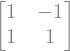

Each step rotates 45 degrees counterclockwise and multiplies length by sqrt(2).


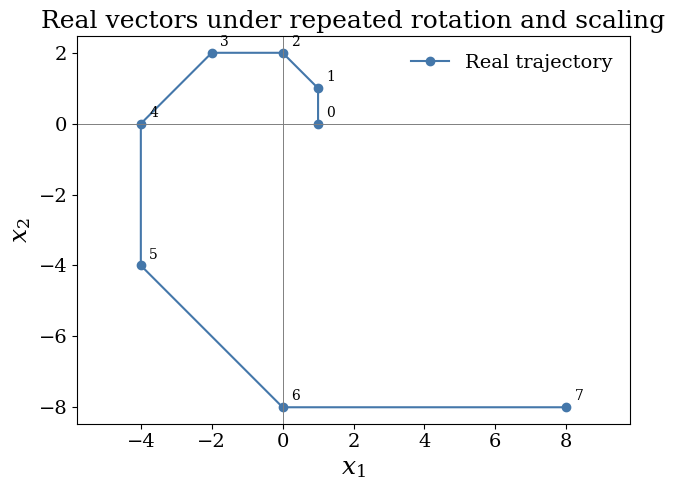

In [11]:
B = sp.eye(2)+R
assert sp.simplify(B*V_complex-V_complex*sp.diag(1+sp.I, 1-sp.I)) == sp.zeros(2)
assert B.T*B == 2*sp.eye(2)
show("Images of the real standard basis (columns)", B)
print("Each step rotates 45 degrees counterclockwise and multiplies length by sqrt(2).")
trajectory = np.array([np.array(B**step*e1, dtype=float).ravel() for step in range(8)])
assert np.allclose(np.linalg.norm(trajectory, axis=1), np.sqrt(2.)**np.arange(8))
fig, ax = plt.subplots(figsize=(6.5, 5))
ax.plot(*trajectory.T, "o-", color=blue, label="Real trajectory")
for step, endpoint in enumerate(trajectory):
    ax.annotate(str(step), endpoint, xytext=(6, 5), textcoords="offset points")
ax.axhline(0, color="gray", linewidth=0.7)
ax.axvline(0, color="gray", linewidth=0.7)
ax.set(xlabel=r"$x_1$", ylabel=r"$x_2$", title="Real vectors under repeated rotation and scaling")
ax.set_aspect("equal", adjustable="datalim")
ax.margins(0.15)
ax.legend()
fig.tight_layout()
plt.show()

## 6. Symmetry permits perpendicular unit directions

Return to $\mathsf A$. Normalize its eigenvectors to form $\mathsf Q$, and verify $\mathsf Q^\top\mathsf Q=\mathsf I$ and $\mathsf A=\mathsf Q\mathsf D\mathsf Q^\top$. Compare the orthogonal coordinates with the earlier unnormalized coordinates. Each $q_jq_j^\top$ is an orthogonal projector onto one eigendirection.

Orthonormal eigenbasis Q

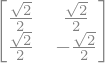

Coordinates Q^T x

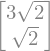

Projection onto the first eigendirection

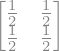

Projection onto the second eigendirection

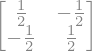

Orthogonal coordinates preserve squared length: 20


In [12]:
Q = V/sp.sqrt(2)
q1, q2 = Q[:, 0], Q[:, 1]
projector1, projector2 = q1*q1.T, q2*q2.T
show("Orthonormal eigenbasis Q", Q)
show("Coordinates Q^T x", sp.simplify(Q.T*x))
show("Projection onto the first eigendirection", projector1)
show("Projection onto the second eigendirection", projector2)
assert Q.T*Q == sp.eye(2)
assert Q.T*A*Q == D and Q*D*Q.T == A
assert projector1+projector2 == sp.eye(2)
assert projector1*projector2 == sp.zeros(2)
assert projector1**2 == projector1 and projector2**2 == projector2
assert 3*projector1+projector2 == A
assert ((Q.T*x).T*(Q.T*x))[0] == (x.T*x)[0]
print("Orthogonal coordinates preserve squared length:", (x.T*x)[0])

### Numerical eigenvectors need residual checks

Use `numpy.linalg.eigh` for a real symmetric matrix. It returns eigenvalues in ascending order. Eigenvector signs can differ from our chosen signs; a repeated eigenspace may have a different orthonormal basis. Check the matrix identities instead of comparing columns entry by entry.

In [13]:
A_numeric = np.array(A, dtype=float)
values, Q_numeric = np.linalg.eigh(A_numeric)
D_numeric = np.diag(values)
show("Numerical eigenvalues (ascending)", values)
show("Numerical unit eigenvectors (columns)", Q_numeric)
residual = A_numeric@Q_numeric-Q_numeric@D_numeric
reconstruction = Q_numeric@D_numeric@Q_numeric.T
assert np.allclose(Q_numeric.T@Q_numeric, np.eye(2), atol=1e-12)
assert np.allclose(residual, 0, atol=1e-12)
assert np.allclose(reconstruction, A_numeric, atol=1e-12)
print(f"Eigenpair residual norm: {np.linalg.norm(residual):.2e}")
print(f"Reconstruction error norm: {np.linalg.norm(reconstruction-A_numeric):.2e}")

Numerical eigenvalues (ascending)

array([1., 3.])

Numerical unit eigenvectors (columns)

array([[-0.707107,  0.707107],
       [ 0.707107,  0.707107]])

Eigenpair residual norm: 0.00e+00
Reconstruction error norm: 6.47e-16


## Your experiments

Predict first, then adapt the preceding cells to check your answers.

1. Use the deck's triangular matrix $\begin{bmatrix}4&1\\0&2\end{bmatrix}$. Find both eigenspaces, build $\mathsf V,\mathsf D$, and verify $\mathsf B\mathsf V=\mathsf V\mathsf D$. Does being triangular make the standard basis an eigenbasis?
2. Compare $\operatorname{diag}(2,2,3)$ with $\begin{bmatrix}2&1&0\\0&2&0\\0&0&3\end{bmatrix}$. Compute both multiplicities for every eigenvalue. Can changing the basis within an eigenspace supply any missing independent direction?
3. Start the population model with $(0,100)^\top$. Change `x0`, compute its eigenbasis coordinates, and construct its formula for $x_k$. Check several powers directly and find its limit.
4. With the original $\mathsf A$, compare repeated actions on $(1,0)^\top$ and $(1,-1)^\top$. Why does the second stay fixed despite the eigenvalue 3?
5. Orthogonally diagonalize $\begin{bmatrix}5&2\\2&5\end{bmatrix}$ and reconstruct it as a sum of scaled projectors. For the nonsymmetric matrix in experiment 1, check the dot product between eigenvectors for distinct eigenvalues. Explain why an eigenbasis need not be orthogonal.

Return to the deck for the general arguments. Numerical eigenpairs are approximations; exact examples and small residuals serve different purposes. The diagonalization formula for powers requires enough independent eigenvectors over the chosen scalar field.

In [14]:
notebook_elapsed = time.perf_counter() - NOTEBOOK_START_TIME
notebook_minutes, notebook_seconds = divmod(notebook_elapsed, 60)
print(
    "Total execution time for this notebook is "
    f"{int(notebook_minutes)} min {notebook_seconds:.1f} sec."
)

Total execution time for this notebook is 0 min 13.2 sec.
